In [1]:
import pandas as pd
import numpy as np
from openpyxl import load_workbook
import pandas as pd
import matplotlib.pyplot as plt 
import matplotlib
from sklearn.model_selection import cross_val_score, train_test_split,GridSearchCV, KFold
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error, mean_squared_error as MSE
from sklearn.neural_network import MLPRegressor

In [2]:
books = pd.read_csv("finetune_data.csv")
books

,FP (K),MolWt,ExactMolWt,HeavyAtomMolWt,LabuteASA,Chi0,HeavyAtomCount,Chi1,BCUT2D_CHGHI,NumValenceElectrons,...,fr_thiocyan,fr_isothiocyan,EState_VSA11,fr_azide,fr_barbitur,fr_alkyl_carbamate,fr_quatN,SOURCE,smiles,type
0,250.15,86.178,86.10955,72.066,40.56396,4.828427,6,2.914214,1.748868,38,...,0,0,0,0,0,0,0,Sheet15,CCCCCC,1
1,269.00,100.205,100.12520,84.077,46.92890,5.535534,7,3.414214,1.796207,44,...,0,0,0,0,0,0,0,Sheet15,CCCCCCC,2
2,263.15,100.205,100.12520,84.077,46.92890,5.698671,7,3.270056,1.882188,44,...,0,0,0,0,0,0,0,Sheet15,CCCCC(C)C,3
3,287.15,114.232,114.14090,96.088,53.29385,6.242641,8,3.914214,1.829101,50,...,0,0,0,0,0,0,0,Sheet15,CCCCCCCC,4
4,279.15,114.232,114.14090,96.088,53.29385,6.405777,8,3.770056,1.901122,50,...,0,0,0,0,0,0,0,Sheet15,CCCCCC(C)C,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
730,383.00,176.256,176.14120,156.096,74.68011,9.071068,12,5.914214,1.885462,74,...,0,0,0,0,0,0,0,Sheet15,CCCCCOCCOCCO,731
731,373.55,190.283,190.15690,168.107,81.04505,10.104450,13,6.201907,2.046425,80,...,0,0,0,0,0,0,0,Sheet15,CCCCOC(C)COC(C)CO,732
732,304.15,115.176,115.09970,102.072,50.43151,5.819991,8,3.931852,2.052398,48,...,0,0,0,0,0,0,0,Sheet15,CCN1CCOCC1,733
733,333.15,120.173,120.02450,112.109,48.26421,5.698671,7,3.308060,1.926854,42,...,0,0,0,0,0,0,0,Sheet15,COC(=O)CCS,734


In [3]:
list_feature_rf = ['Ipc', 'HeavyAtomMolWt', 'TPSA', 'VSA_EState3', 'AvgIpc', 'Chi1', 'VSA_EState8', 'BertzCT', 'HallKierAlpha', 'BCUT2D_MRHI', 'ExactMolWt', 'EState_VSA2', 'qed', 'MolLogP', 'Chi4v', 'MolWt', 'LabuteASA', 'Chi3v', 'MaxAbsEStateIndex', 'NumHDonors', 'MaxPartialCharge']
x = books[list_feature_rf]
x

,Ipc,HeavyAtomMolWt,TPSA,VSA_EState3,AvgIpc,Chi1,VSA_EState8,BertzCT,HallKierAlpha,BCUT2D_MRHI,...,EState_VSA2,qed,MolLogP,Chi4v,MolWt,LabuteASA,Chi3v,MaxAbsEStateIndex,NumHDonors,MaxPartialCharge
0,20.98630,72.066,0.00,0.000000,1.614331,2.914214,4.463611,12.00000,0.00,4.307622,...,0.000000,0.462954,2.5866,0.500000,86.178,40.56396,0.957107,2.231806,0,-0.053580
1,35.50961,84.077,0.00,0.000000,1.690934,3.414214,4.491389,19.21928,0.00,4.354233,...,0.000000,0.476310,2.9767,0.676777,100.205,46.92890,1.207107,2.245694,0,-0.053330
2,29.01955,84.077,0.00,0.000000,1.612197,3.270056,6.785417,29.01955,0.00,4.417096,...,0.000000,0.511270,2.8326,0.612372,100.205,46.92890,1.135028,2.273472,0,-0.047130
3,61.49961,96.088,0.00,0.000000,1.808812,3.914214,4.511797,25.01955,0.00,4.386659,...,0.000000,0.480611,3.3668,0.853553,114.232,53.29385,1.457107,2.255899,0,-0.053320
4,48.27551,96.088,0.00,0.000000,1.664673,3.770056,6.825046,37.30297,0.00,4.438797,...,0.000000,0.492147,3.2227,0.802586,114.232,53.29385,1.385028,2.287361,0,-0.047130
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
730,488.92510,156.096,38.69,8.373106,2.098391,5.914214,4.741308,66.17390,-0.12,4.362655,...,6.606882,0.536466,1.2021,0.840649,176.256,74.68011,1.499862,8.373106,1,0.070112
731,660.13770,168.107,38.69,8.695977,2.143304,6.201907,7.401322,106.34300,-0.12,4.508217,...,18.814810,0.590656,1.5890,0.829448,190.283,81.04505,1.772821,8.695977,1,0.078009
732,91.36758,102.072,12.47,0.000000,1.903491,3.931852,7.447778,59.54888,-0.08,4.573167,...,0.000000,0.488308,0.3385,0.917392,115.176,50.43151,1.550918,5.159861,0,0.059362
733,31.91664,112.109,26.30,0.000000,1.679823,3.308060,0.000000,62.71013,-0.18,7.797711,...,5.969305,0.423496,0.4793,0.375923,120.173,48.26421,0.767205,10.140690,1,0.305832


In [4]:
y = books['FP (K)']

In [5]:
list_params = []
for n in range(1, 4):  # 1到3层隐藏层
    for h1 in [64, 32, 16]:  # 减少搜索空间
        # 更合理的神经元数量递减
        if n == 1:
            hidden_sizes = [h1]
        elif n == 2:
            hidden_sizes = [h1, max(8, h1//2)]  # 确保至少8个神经元
        elif n == 3:
            hidden_sizes = [h1, max(8, h1//2), max(4, h1//4)]  # 确保至少4个神经元
        
        # 更精细的学习率和正则化搜索
        for l in [0.001, 0.005, 0.01]:
            for alpha in [0.001, 0.01, 0.1]:
                P = [hidden_sizes, l, alpha]
                list_params.append(P)

print(f"总超参数组合数: {len(list_params)}")
# 外循环：10折交叉验证
kf = KFold(n_splits=5, shuffle=True, random_state=42)
list_best_params = []
K = 1
for train_index, test_index in kf.split(x):
    # 根据索引分割数据
    x_train, x_test = x.iloc[train_index], x.iloc[test_index]
    y_train, y_test = y.iloc[train_index], y.iloc[test_index]
    
    from sklearn.preprocessing import StandardScaler
    # 创建标准化器，并在训练集上拟合
    scaler_x = StandardScaler()
    scaler_feature = scaler_x.fit(x_train)
    
    # 使用相同的标准化器转换训练集和测试集
    x_train_std = scaler_feature.transform(x_train)
    x_test_std = scaler_feature.transform(x_test)
    
    # 内循环：在训练集上进行10折交叉验证调整超参数
    best_score = -np.inf
    best_params = {}

    # 遍历超参数网格
    for params in list_params:
        # 初始化模型
        model = MLPRegressor(
            hidden_layer_sizes=params[0],
            learning_rate_init=params[1],
            alpha=params[2],
            activation = 'relu',
            max_iter=10000
        )

        # 使用cross_val_score进行10折交叉验证
        cv_scores = cross_val_score(model, x_train_std, y_train, cv=5, scoring='r2')

        # 计算平均R2分数
        mean_score = np.mean(cv_scores)

        # 记录最佳参数组合
        if mean_score > best_score:
            best_score = mean_score
            best_params = params
    
    print(f"k-kold {K}:")
    K = K+1
    
    print(f"Test fold {test_index + 1}:")
    print(f"best_score {best_score}:")
    print(f"Best hyperparameters: {best_params}")
    list_best_params.append(best_params)
    
    
    # 使用最佳参数训练模型
    model = MLPRegressor(hidden_layer_sizes=best_params[0],
                        learning_rate_init=best_params[1],
                        alpha=best_params[2],
                         activation = 'relu',
                        max_iter=50000
                        )
    model.fit(x_train_std, y_train)
    
    # 在测试集上评估模型
    predictions = model.predict(x_test_std)
    test_score = r2_score(y_test, predictions)
    test_MSE = MSE(y_test, predictions)
    print(f"Test R2 score: {test_score}")
    print(f"Test MSE: {test_MSE}")

总超参数组合数: 81


D:\Anaconda\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (10000) reached and the optimization hasn't converged yet.
  warnings.warn(
D:\Anaconda\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (10000) reached and the optimization hasn't converged yet.
  warnings.warn(
D:\Anaconda\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (10000) reached and the optimization hasn't converged yet.
  warnings.warn(
D:\Anaconda\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (10000) reached and the optimization hasn't converged yet.
  warnings.warn(


k-kold 1:
Test fold [  3   6   8  11  24  30  31  32  34  40  50  55  64  66  67  68  73  77
  78  79  82  85  87  97  98 102 110 111 119 121 138 140 156 169 175 193
 197 199 200 205 210 211 212 214 216 219 228 232 240 245 248 251 255 260
 266 267 276 282 287 291 292 295 300 303 312 315 317 320 328 329 330 337
 339 345 351 352 356 357 361 362 364 369 376 382 383 384 394 399 405 410
 412 423 426 430 432 440 445 449 451 466 468 479 483 488 500 501 523 527
 528 529 533 535 537 539 543 544 546 558 583 584 587 589 610 612 619 622
 627 629 636 649 657 659 660 663 666 668 672 677 688 689 695 699 709 714
 717 719 728 740 747 758 762 764 765 771 775 777 782 784 792 808 814 818
 820 823 824 826]:
best_score 0.8038043031995492:
Best hyperparameters: [[16, 8, 4], 0.01, 0.01]
Test R2 score: 0.9017190557202415
Test MSE: 283.6345619401464


D:\Anaconda\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (10000) reached and the optimization hasn't converged yet.
  warnings.warn(
D:\Anaconda\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (10000) reached and the optimization hasn't converged yet.
  warnings.warn(
D:\Anaconda\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (10000) reached and the optimization hasn't converged yet.
  warnings.warn(
D:\Anaconda\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (10000) reached and the optimization hasn't converged yet.
  warnings.warn(
D:\Anaconda\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic O

k-kold 2:
Test fold [  7  12  19  25  29  42  43  44  45  52  56  57  61  62  70  71  74  75
  80  83  84  90  91  93  95 105 109 115 132 133 134 136 137 141 146 149
 159 164 165 166 168 177 178 179 182 183 194 209 213 221 224 235 236 249
 261 265 286 293 297 301 307 310 324 327 332 333 334 335 343 347 363 366
 368 378 381 389 395 396 397 406 421 424 425 427 429 433 435 441 443 444
 448 454 458 463 465 480 482 486 494 498 508 513 514 515 519 530 536 538
 540 542 545 548 550 552 553 555 568 573 576 577 582 588 595 597 599 603
 605 614 621 626 634 635 641 667 669 681 686 692 696 698 712 718 722 724
 726 731 733 738 745 746 749 750 755 760 761 763 773 776 778 787 789 804
 805 807 809 815]:
best_score 0.8266447348349424:
Best hyperparameters: [[32, 16], 0.005, 0.1]
Test R2 score: 0.8922233772455018
Test MSE: 350.5171659787814


D:\Anaconda\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (10000) reached and the optimization hasn't converged yet.
  warnings.warn(
D:\Anaconda\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (10000) reached and the optimization hasn't converged yet.
  warnings.warn(
D:\Anaconda\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (10000) reached and the optimization hasn't converged yet.
  warnings.warn(
D:\Anaconda\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (10000) reached and the optimization hasn't converged yet.
  warnings.warn(
D:\Anaconda\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic O

k-kold 3:
Test fold [  1   4  10  13  16  20  23  26  39  47  51  58  60  69  76  89  94 101
 108 114 117 118 125 126 127 142 143 145 150 154 155 170 173 174 176 180
 185 186 189 196 204 222 223 229 237 238 239 246 250 257 258 262 264 269
 272 273 275 278 279 285 288 290 299 305 306 308 311 313 319 321 322 325
 336 341 342 350 353 354 355 358 360 370 371 372 391 400 408 409 413 417
 418 431 434 437 446 447 450 452 457 474 478 484 487 491 495 496 502 507
 517 522 524 526 531 532 549 559 569 570 571 585 586 590 594 596 602 604
 616 618 623 631 632 642 645 653 656 661 670 671 674 676 680 690 693 694
 704 713 715 723 736 737 744 753 757 766 768 772 781 790 793 794 798 812
 817 819 827]:
best_score 0.8313470665652904:
Best hyperparameters: [[16, 8, 4], 0.01, 0.001]
Test R2 score: 0.8284563618445236
Test MSE: 664.13697552282


D:\Anaconda\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (10000) reached and the optimization hasn't converged yet.
  warnings.warn(
D:\Anaconda\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (10000) reached and the optimization hasn't converged yet.
  warnings.warn(
D:\Anaconda\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (10000) reached and the optimization hasn't converged yet.
  warnings.warn(
D:\Anaconda\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (10000) reached and the optimization hasn't converged yet.
  warnings.warn(
D:\Anaconda\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic O

k-kold 4:
Test fold [  9  17  18  27  37  38  46  49  54 104 112 113 116 120 123 124 128 130
 144 147 148 151 152 153 158 163 172 181 184 187 191 195 198 203 208 220
 225 226 227 230 233 234 247 254 256 259 263 268 280 281 283 284 294 298
 302 304 318 323 326 348 349 359 365 374 375 377 385 387 401 403 404 411
 415 416 420 422 438 439 442 453 464 469 470 471 473 481 489 497 504 506
 510 512 516 518 520 534 551 560 572 579 580 581 591 592 598 600 606 607
 608 609 611 617 624 625 628 630 633 637 638 639 640 644 650 651 652 654
 658 665 673 678 679 683 685 691 697 705 706 707 711 716 721 732 734 735
 743 752 754 756 759 769 780 785 786 788 791 796 797 799 800 801 802 803
 811 813 816]:
best_score 0.7759481851616552:
Best hyperparameters: [[16, 8, 4], 0.001, 0.001]
Test R2 score: 0.8617863496969576
Test MSE: 337.0476491750018


D:\Anaconda\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (10000) reached and the optimization hasn't converged yet.
  warnings.warn(
D:\Anaconda\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (10000) reached and the optimization hasn't converged yet.
  warnings.warn(
D:\Anaconda\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (10000) reached and the optimization hasn't converged yet.
  warnings.warn(
D:\Anaconda\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (10000) reached and the optimization hasn't converged yet.
  warnings.warn(
D:\Anaconda\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic O

k-kold 5:
Test fold [  2   5  14  15  21  22  28  33  35  36  41  48  53  59  63  65  72  81
  86  88  92  96  99 100 103 106 107 122 129 131 135 139 157 160 161 162
 167 171 188 190 192 201 202 206 207 215 217 218 231 241 242 243 244 252
 253 270 271 274 277 289 296 309 314 316 331 338 340 344 346 367 373 379
 380 386 388 390 392 393 398 402 407 414 419 428 436 455 456 459 460 461
 462 467 472 475 476 477 485 490 492 493 499 503 505 509 511 521 525 541
 547 554 556 557 561 562 563 564 565 566 567 574 575 578 593 601 613 615
 620 643 646 647 648 655 662 664 675 682 684 687 700 701 702 703 708 710
 720 725 727 729 730 739 741 742 748 751 767 770 774 779 783 795 806 810
 821 822 825]:
best_score 0.7425528997509674:
Best hyperparameters: [[32, 16, 8], 0.005, 0.01]
Test R2 score: 0.841250098453258
Test MSE: 419.1915045738805


In [9]:
list_best_params = [[[16, 8, 4], 0.01, 0.01],
                    [[32, 16], 0.005, 0.1],
                    [[16, 8, 4], 0.01, 0.001],
                    [[16, 8, 4], 0.001, 0.001],
                    [[32, 16, 8], 0.005, 0.01]
                   ]

Train
Average R2 Score: 0.9593658651275707
Average RMSE: 10.743340750388112
Average MAE: 7.593371952700517
Test
Average R2 Score: 0.8495227945774768
Average RMSE: 20.14807541566217
Average MAE: 12.262949011316369


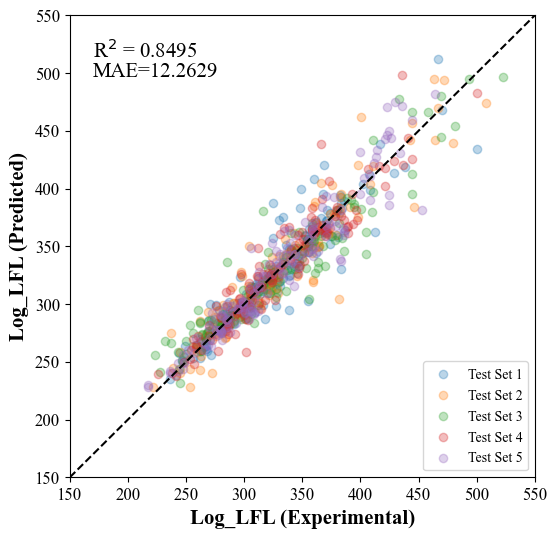

In [57]:
list_predictions = []
list_y = []
i = 0
from sklearn.preprocessing import StandardScaler
kf = KFold(n_splits=5, shuffle=True, random_state=42)
Train_r2 = []
Train_MAE = []
Train_MSE = []
Test_r2 = []
Test_MAE = []
Test_MSE = []
for train_index, test_index in kf.split(x):
    # 根据索引分割数据
    x_train, x_test = x.iloc[train_index], x.iloc[test_index]
    y_train, y_test = y.iloc[train_index], y.iloc[test_index]
    
    # 创建标准化器，并在训练集上拟合
    scaler_x = StandardScaler()
    scaler_feature = scaler_x.fit(x_train)
    
    # 使用相同的标准化器转换训练集和测试集
    x_train_std = scaler_feature.transform(x_train)
    x_test_std = scaler_feature.transform(x_test)
    
    params = list_best_params[i]

    model = MLPRegressor(
            hidden_layer_sizes=params[0],
            learning_rate_init=params[1],
            alpha=params[2],
        activation = 'relu',
            max_iter=50000
        )
    model.fit(x_train_std, y_train)

    predictions_train = model.predict(x_train_std)
    train_score = r2_score(y_train, predictions_train)
    train_MAE = mean_absolute_error(y_train, predictions_train)
    train_MSE = MSE(y_train, predictions_train)
    Train_r2.append(train_score)
    Train_MAE.append(train_MAE)
    Train_MSE.append(train_MSE)

    # 在测试集上评估模型
    predictions_test = model.predict(x_test_std)
    test_score = r2_score(y_test, predictions_test)
    test_MAE = mean_absolute_error(y_test, predictions_test)
    test_MSE = MSE(y_test, predictions_test)
    Test_r2.append(test_score)
    Test_MAE.append(test_MAE)
    Test_MSE.append(test_MSE)
    
    list_predictions.append(predictions_test.tolist())
    list_y.append(y_test)
    i = i+1
# 将收集的结果转换为numpy数组
list_predictions_one = [item for sublist in list_predictions for item in sublist]
list_y_one = [item for sublist in list_y for item in sublist]

# 计算R²分数的平均值
print("Train")
print(f"Average R2 Score: {np.mean(Train_r2)}")
print(f"Average RMSE: {np.mean(np.sqrt(Train_MSE))}")
print(f"Average MAE: {np.mean(Train_MAE)}")

print("Test")
print(f"Average R2 Score: {np.mean(Test_r2)}")
print(f"Average RMSE: {np.mean(np.sqrt(Test_MSE))}")
print(f"Average MAE: {np.mean(Test_MAE)}")

formatted_score = f"{np.mean(Test_r2):.4f}"
formatted_RMSE = f"{np.mean(np.sqrt(Test_MSE)):.4f}"
formatted_MAE = f"{np.mean(Test_MAE):.4f}"

matplotlib.rcParams['font.family'] = 'Times New Roman'
# 绘制散点图和对角线
plt.figure(figsize=(6, 6))
for i, (exp, preds) in enumerate(zip(list_y, list_predictions)):
    plt.scatter(exp, preds, alpha=0.3
                , label=f'Test Set {i+1}'
               )

plt.plot([150, 550], [150, 550], 'k--')  # 绘制对角线
plt.xlabel('Log_LFL (Experimental)', fontsize=15, fontweight='bold')
plt.ylabel('Log_LFL (Predicted)', fontsize=15, fontweight='bold')
plt.annotate(f'R$^2$ = {formatted_score}', xy=(1, 1), xycoords='axes fraction',
             xytext=(0.05, 0.95), textcoords='axes fraction',
             fontsize=15, ha='left', va='top', color='black')
plt.annotate(f'MAE={formatted_MAE}', xy=(1, 0.95), xycoords='axes fraction',
             xytext=(0.05, 0.9), textcoords='axes fraction',
             fontsize=15, ha='left', va='top', color='black')

# 添加图例
plt.legend(loc='lower right')
plt.xlim(150, 550)
plt.ylim(150, 550)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.show()

In [12]:
SMILES = books[["smiles","FP (K)"]]

In [25]:
list_SMILES = pd.DataFrame()
for train_index, test_index in kf.split(x):
    # 根据索引分割数据
    SMILES_test = SMILES.iloc[test_index]
    
    list_SMILES = pd.concat([list_SMILES, SMILES_test], axis = 0).reset_index(drop=True)
    i = i+1
list_SMILES

,smiles,FP (K)
0,CCCCC(C)C,263.15
1,CCC(C)C(C)CC,280.65
2,CC(C)(C)CC(C)(C)C,278.15
3,CCCCCCCCCCCCCCCC,407.05
4,CCCCCCC(C)CC,319.15
...,...,...
730,CCOC(=O)CC#N,383.15
731,C1=CON=C1,285.00
732,CCS(=O)(=O)Cl,356.48
733,CCCCCOCCO,348.15


In [59]:
predict_df = pd.DataFrame({'FP': list_y_one, 'predict': list_predictions_one})
predict_df = pd.concat([list_SMILES, predict_df], axis = 1)
predict_df

,smiles,FP (K),FP,predict
0,CCCCC(C)C,263.15,263.15,267.375005
1,CCC(C)C(C)CC,280.65,280.65,276.617105
2,CC(C)(C)CC(C)(C)C,278.15,278.15,295.120706
3,CCCCCCCCCCCCCCCC,407.05,407.05,413.024433
4,CCCCCCC(C)CC,319.15,319.15,313.158341
...,...,...,...,...
730,CCOC(=O)CC#N,383.15,383.15,336.944384
731,C1=CON=C1,285.00,285.00,287.376271
732,CCS(=O)(=O)Cl,356.48,356.48,358.062304
733,CCCCCOCCO,348.15,348.15,342.410840


In [61]:
from pandas import ExcelWriter

with ExcelWriter('FP-ANN.xlsx') as writer:       
    predict_df.to_excel(writer,sheet_name='ANN')

In [79]:
books = pd.read_excel("FP-SMILES.xlsx")
books

,Unnamed: 0,smiles,FP (K),F-DMPNN+1D-CNN
0,2,CCCCC(C)C,263.15,265.217055
1,10,CCC(C)C(C)CC,280.65,286.702644
2,23,CC(C)(C)CC(C)(C)C,278.15,282.930651
3,30,CCCCCCCCCCCCCCCC,407.05,404.836292
4,31,CCCCCCC(C)CC,319.15,311.648944
...,...,...,...,...
730,714,CCOC(=O)CC#N,383.15,364.148726
731,716,C1=CON=C1,285.00,278.174264
732,717,CCS(=O)(=O)Cl,356.48,359.833434
733,728,CCCCCOCCO,348.15,341.700633


In [ ]:
test_r2 = r2_score(list_test_y_one, list_test_predictions_one)
test_rmse = np.sqrt(mean_squared_error(list_test_y_one, list_test_predictions_one))
test_mae = mean_absolute_error(list_test_y_one, list_test_predictions_one)